# Adopcion de la AI en Argentina y en el mundo


![PIC](a.jpg)
### Que tanta gente usa la AI de manera cotidiana y como esto evoluciona a lo largo del tiempo
Trabajo final de Estadística — Escuela Da Vinci · Santiago Alejo Iriarte Perez ACN5AV


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from scipy import stats

## 1. Introducción
**Objetivo:** medir qué proporción de la gente usa IA generativa, cómo evoluciona entre 2025 y 2026, y cómo se ubica Argentina frente al mundo.

**Hipótesis:** la adopción crece rápido pero de forma desigual: los países más ricos adoptan más y la diferencia con los más pobres se agranda.

## 2. Datos y metodología
- **Microsoft AI Diffusion Report (Q2 2026):** el % de gente de 15 a 64 años que usó IA, en 147 países y 4 períodos. No es una encuesta, es una estimación que hace Microsoft con datos de uso de Windows.
- **Our World in Data (OWID):** de acá saqué el código de cada país, el PIB per cápita y la región.
- **Google Trends:** cuánto se busca IA en Argentina semana a semana (nov 2025 – nov 2026).

Todo lo hice en Python con Jupyter: pandas para limpiar y unir, matplotlib y plotly para los gráficos, scipy para la correlación.

In [29]:
ms = pd.read_csv('microsoft_ai_diffusion_q2_2026.csv', encoding='mac_roman') #"aclarar"
print(ms.shape); ms.head(5)

(147, 5)


,Economy,H1 2025 AI Diffusion,H2 2025 AI Diffusion,Q1 2026 AI Diffusion,Q2 2026 AI Diffusion
0,United Arab Emirates,59.40%,64.00%,70.10%,73.3%
1,Singapore,58.60%,60.90%,63.40%,64.3%
2,Norway,45.30%,46.40%,48.60%,49.4%
3,Ireland,41.70%,44.60%,48.40%,49.9%
4,France,40.90%,44.00%,47.80%,49.6%


Cargo el archivo de Microsoft. Lo tuve que abrir con `mac_roman` porque con la codificación normal "Türkiye" salía con símbolos raros.

In [30]:
PERIODOS = ['H1 2025', 'H2 2025', 'Q1 2026', 'Q2 2026']
ms.columns = ['pais'] + PERIODOS
for p in PERIODOS:
    ms[p] = ms[p].str.rstrip('%').astype(float)
print('Nulos:', ms.isna().sum().sum()); ms.describe()

Nulos: 0


,H1 2025,H2 2025,Q1 2026,Q2 2026
count,147.000000,147.000000,147.000000,147.000000
mean,16.224490,17.393878,19.070068,19.866667
std,10.693972,11.369740,12.197341,12.609174
min,4.600000,5.100000,5.700000,6.100000
25%,8.550000,9.050000,10.100000,10.400000
50%,12.500000,13.400000,14.800000,15.400000
75%,22.050000,23.600000,26.100000,27.150000
max,59.400000,64.000000,70.100000,73.300000


Como primer paso hacemos una limpieza de los datos del primer dataset sacando el caracter % para poder analizar los valores convirtiendolos en float, ademas como primer dato ya podemos observar un uso creciente ya que la media aumenta periodo a periodo.

In [31]:
owid = pd.read_csv('estimated-share-people-generative-ai.csv', encoding='mac_roman')
owid.head(20)



,Entity,Code,Day,Estimated share of working-age adults who use generative AI,GDP per capita,World region according to OWID
0,Afghanistan,AFG,2025-06-30,5.1,1964.4523,Asia
1,Afghanistan,AFG,2025-12-31,5.6,1964.4523,Asia
2,Afghanistan,AFG,2026-03-31,6.1,1964.4523,Asia
3,Albania,ALB,2025-06-30,15.8,22724.2930,Europe
4,Albania,ALB,2025-12-31,16.5,22724.2930,Europe
5,Albania,ALB,2026-03-31,18.5,22724.2930,Europe
6,Algeria,DZA,2025-06-30,11.3,15882.7140,Africa
7,Algeria,DZA,2025-12-31,12.0,15882.7140,Africa
8,Algeria,DZA,2026-03-31,13.2,15882.7140,Africa
9,Angola,AGO,2025-06-30,8.9,8760.1900,Africa


Cargo el segundo dataset, el de OWID. De acá me interesan el código ISO, el PIB y la región de cada país.

In [32]:
owid.shape

(444, 6)

In [33]:
owid['Entity'].nunique()

148

OWID tiene 444 filas pero 148 países. Es porque cada país aparece 3 veces, una por fecha. Además hay una fila "World" que es el promedio mundial, no un país.

In [34]:

paises_ms = set(ms['pais'].dropna().unique())
paises_owid = set(owid['Entity'].dropna().unique())


faltan_en_owid = paises_ms - paises_owid


faltan_en_ms = paises_owid - paises_ms

print("Están en MS pero faltan en OWID:", faltan_en_owid)
print("Están en OWID pero faltan en MS:", faltan_en_ms)


Están en MS pero faltan en OWID: {"Cote D'Ivoire", 'Bosnia And Herzegovina', 'Congo (DRC)', 'Türkiye', 'Czech Republic'}
Están en OWID pero faltan en MS: {'Democratic Republic of Congo', 'Turkey', 'Czechia', 'Bosnia and Herzegovina', "Cote d'Ivoire", 'World'}


Antes de unir las tablas comparé los nombres de los países de las dos fuentes. Me di cuenta de algo curioso: hay 5 países escritos distinto en cada una, por ejemplo "Czech Republic" y "Czechia". Es el mismo país, así que hay que corregirlos para que no queden sin datos.

In [35]:
owid.groupby('Entity')[['GDP per capita', 'Code', 'World region according to OWID']].nunique().max()

GDP per capita                    1
Code                              1
World region according to OWID    1
dtype: int64

Chequeé si el PIB, el código y la región cambian entre las 3 fechas de cada país. Da 1 en todo, o sea que son iguales. Entonces me puedo quedar con una sola fila por país sin perder nada.

In [36]:
ms['pais'] = ms['pais'].replace({
    'Czech Republic': 'Czechia',
    'Türkiye': 'Turkey',
     "Cote D'Ivoire": "Cote d'Ivoire",
    'Congo (DRC)': 'Democratic Republic of Congo',
   'Bosnia And Herzegovina': 'Bosnia and Herzegovina',
})

owid_paises = owid.drop_duplicates('Entity')
owid_paises = owid_paises[['Entity', 'Code', 'GDP per capita', 'World region according to OWID']]
owid_paises.columns = ['pais', 'iso3', 'pib_per_capita', 'region']
df = ms.merge(owid_paises, on='pais', how='left')
print(df.shape)
print('Sin código ISO:', df['iso3'].isna().sum())

(147, 8)
Sin código ISO: 0


Corregí los 5 nombres, dejé una fila por país en OWID y uní las dos tablas.
- Usé `how='left'` para no perder ningún país de Microsoft.
- Me quedaron 147 países y 8 columnas (las 5 de Microsoft + código, PIB y región).
- Ningún país quedó sin código ISO, o sea que se unieron todos.

El **código ISO3** es un código de 3 letras por país (ARG, USA, BRA). Lo uso porque los nombres cambian según la fuente y el código no.

In [37]:
try:
    largo = df.melt(id_vars=['pais', 'iso3'], value_vars=PERIODOS, var_name='periodo', value_name='adopcion')
    fig = px.choropleth(
        largo, 
        locations='iso3', 
        color='adopcion', 
        hover_name='pais', 
        animation_frame='periodo',
        range_color=(0, 75), 
        color_continuous_scale='Blues', 
        labels={'adopcion': '% usa IA'},
        title='Adopción de IA generativa por país (Microsoft AI Diffusion)'
    )
    fig.update_layout(
    width=1100,
    height=700 
)
    fig.show()
    
except Exception as e:
    print(f"Error al generar el mapa: {e}")

Mapa animado por período. Para pintar cada país plotly necesita el código ISO3, por eso lo hice después de unir con OWID. Fijé la escala de 0 a 75 en todos los períodos para que los colores se puedan comparar.

In [38]:
df['copiado'] = df.duplicated(
    subset=['H1 2025',	'H2 2025',	'Q1 2026',	'Q2 2026'], keep=False
)

cantidad_copiados = df['copiado'].sum()
print(f'Cantidad de registros copiados: {cantidad_copiados}')
filas_copiadas = df[df['copiado']]
display(filas_copiadas)

Cantidad de registros copiados: 36


,pais,H1 2025,H2 2025,Q1 2026,Q2 2026,iso3,pib_per_capita,region,copiado
92,Angola,8.9,9.7,10.9,11.4,AGO,8760.1900,Africa,True
93,Madagascar,8.9,9.7,10.9,11.4,MDG,1668.4770,Africa,True
94,Malawi,8.9,9.7,10.9,11.4,MWI,1623.0217,Africa,True
95,Mozambique,8.9,9.7,10.9,11.4,MOZ,1450.9596,Africa,True
96,French Guiana,8.3,9.0,10.3,11.3,GUF,NaN,South America,True
97,Guyana,8.3,9.0,10.3,11.3,GUY,83658.6800,South America,True
98,Suriname,8.3,9.0,10.3,11.3,SUR,19357.3900,South America,True
99,Venezuela,8.3,9.0,10.3,11.3,VEN,NaN,South America,True
100,Benin,8.7,9.3,10.1,10.4,BEN,4116.2153,Africa,True
101,Burkina Faso,8.7,9.3,10.1,10.4,BFA,2624.8286,Africa,True


Revisando la tabla vi que muchos países tienen **exactamente los mismos 4 valores**. Por ejemplo Nigeria, Ghana, Mali y otros 9 países de África tienen todos 8,7 → 9,3 → 10,1 → 10,4.

En la documentación de Microsoft dice que, cuando no tiene datos suficientes de un país, le pone **el promedio de su región**. Así que estos países no fueron medidos de verdad.

Con `duplicated(keep=False)` marqué a todos los que se repiten: son 36. Uso `keep=False` porque ninguno es "el original", a todos les pusieron el mismo promedio.

In [39]:
medidos = df[~df['copiado']].copy()
medidos.head()
medidos.describe()

,H1 2025,H2 2025,Q1 2026,Q2 2026,pib_per_capita
count,111.000000,111.000000,111.000000,111.000000,109.000000
mean,19.011712,20.363063,22.294595,23.210811,31613.961707
std,10.921336,11.605210,12.406735,12.812411,26897.301407
min,4.600000,5.100000,5.700000,6.100000,2677.893800
25%,10.850000,11.650000,12.900000,13.350000,11357.916000
50%,16.700000,17.800000,20.100000,20.700000,22314.217000
75%,25.400000,27.150000,29.600000,30.950000,48232.664000
max,59.400000,64.000000,70.100000,73.300000,139592.610000


Saqué los 36 copiados y me quedé con los **111 países medidos**. Con esta tabla hago todo el análisis.

- La mediana de Q2 2026 subió de 15,4 % (con los 147) a 20,7 %. Tiene sentido: casi todos los copiados eran países con poca adopción.
- La media (23,2 %) es más alta que la mediana (20,7 %). Es porque hay pocos países con valores muy altos, como Emiratos (73 %) y Singapur (64 %), que tiran la media para arriba. Por eso para describir al país típico uso la mediana.
- 2 países medidos no tienen PIB en OWID (Taiwán y Cuba), por eso el PIB tiene 109 datos.

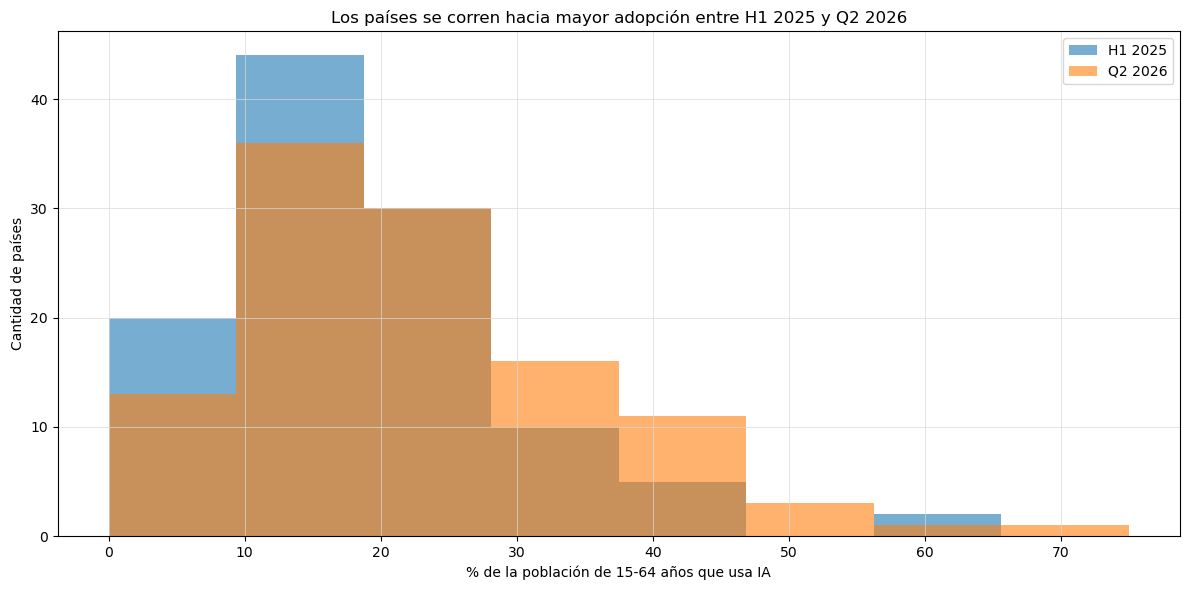

Cantidad de intervalos (Sturges): 8


In [40]:
bins = int(np.ceil(1 + np.log2(len(medidos))))
limites = np.linspace(0, 75, bins + 1)

fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(medidos['H1 2025'], bins=limites, alpha=0.6, label='H1 2025')
ax.hist(medidos['Q2 2026'], bins=limites, alpha=0.6, label='Q2 2026')

ax.set_xlabel('% de la población de 15-64 años que usa IA')
ax.set_ylabel('Cantidad de países')
ax.set_title('Los países se corren hacia mayor adopción entre H1 2025 y Q2 2026')
ax.legend()
ax.grid(True, linewidth=0.5, color='0.85')
plt.tight_layout()
plt.show()
print('Cantidad de intervalos (Sturges):', bins)

**Histograma.** Comparo cómo se reparten los países en el primer y el último período.
- El eje X es el % de adopción de cada país y el eje Y es cuántos países hay en cada rango. No son personas ni edades.
- La cantidad de barras sale de la regla de Sturges (1 + log2(n)): con 111 países da 8.
- Usé los mismos límites en los dos períodos, si no las alturas no se podrían comparar.

Lo que se ve: a la izquierda hay menos países en Q2 2026 que en H1 2025. No es que se use menos IA, es que esos países **se movieron a la derecha**, a rangos de más adopción. Además tiene una cola larga a la derecha por los pocos países muy altos.

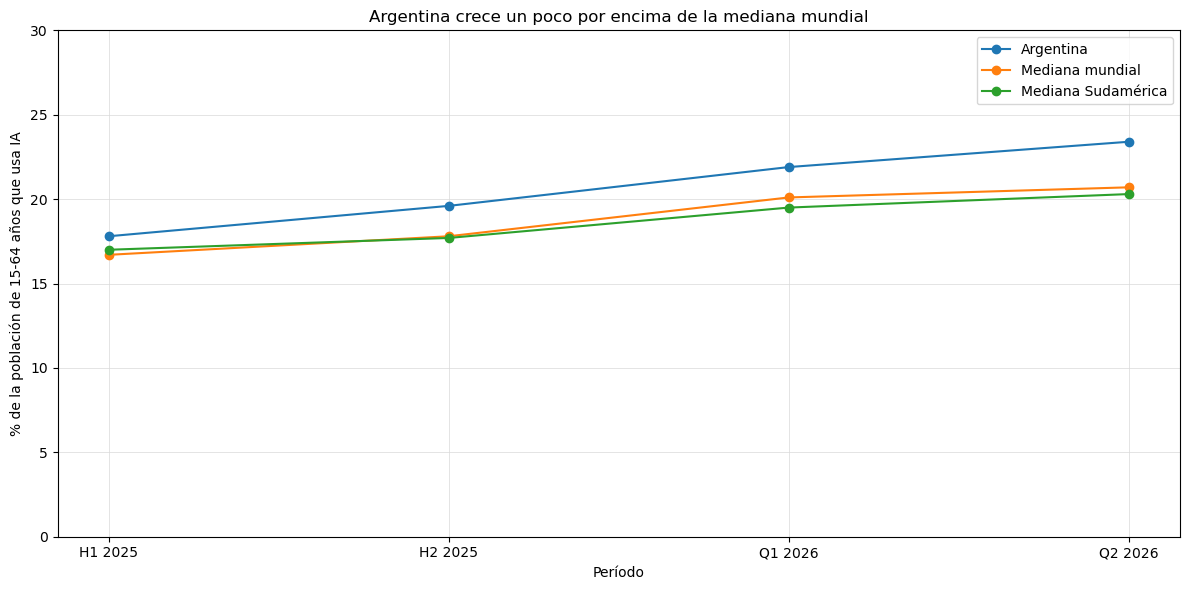

In [48]:
argentina = medidos.loc[medidos['pais'] == 'Argentina', PERIODOS].iloc[0]
mediana_mundo = medidos[PERIODOS].median()
mediana_sudam = medidos.loc[medidos['region'] == 'South America', PERIODOS].median()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(PERIODOS, argentina, marker='o', label='Argentina')
ax.plot(PERIODOS, mediana_mundo, marker='o', label='Mediana mundial')
ax.plot(PERIODOS, mediana_sudam, marker='o', label='Mediana Sudamérica')

ax.set_ylim([0, 30]) 
ax.set_xlabel('Período')
ax.set_ylabel('% de la población de 15-64 años que usa IA')
ax.set_title('Argentina crece un poco por encima de la mediana mundial')
ax.legend()
ax.grid(True, linewidth=0.5, color='0.85')
plt.tight_layout()
plt.show()

Comparo Argentina con la mediana mundial y la de Sudamérica. Puse solo 3 líneas para que no se mezclen y el eje arranca en 0 para no exagerar el crecimiento.

Argentina pasó de **17,8 % a 23,4 %** (+5,6 puntos). En Q2 2026 está un poco arriba de la mediana mundial (20,7 %) y de la de Sudamérica (20,3 %).

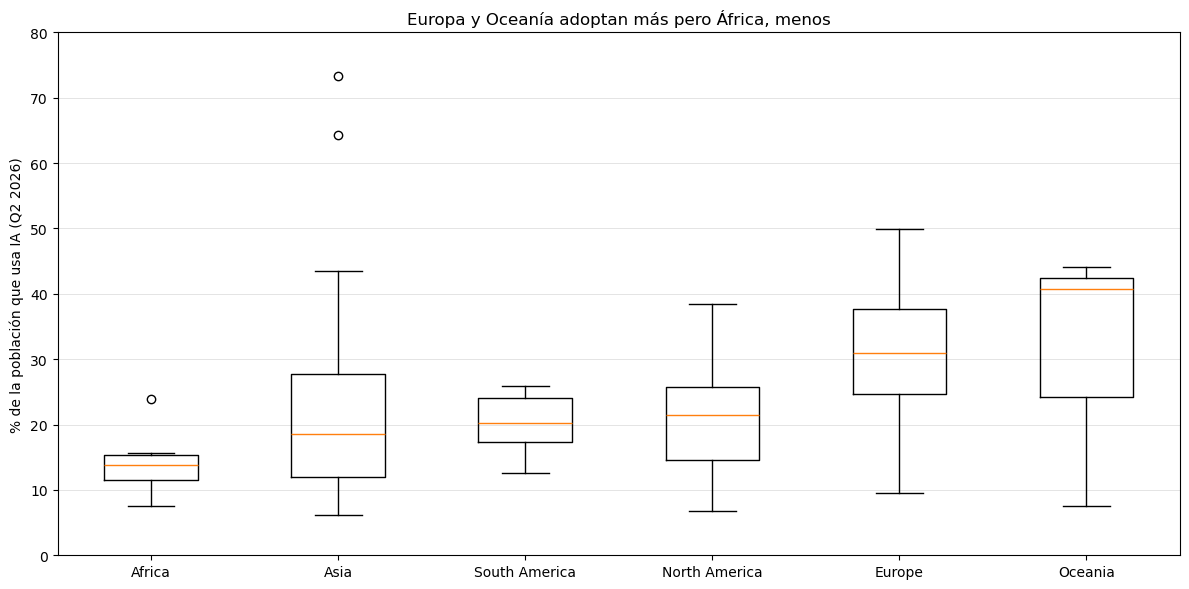

In [42]:
regiones = medidos.groupby('region')['Q2 2026'].median().sort_values().index 

fig, ax = plt.subplots(figsize=(12, 6))
ax.boxplot([medidos.loc[medidos['region'] == r, 'Q2 2026'] for r in regiones], tick_labels=regiones)
ax.set_ylim([0, 80])
ax.set_ylabel('% de la población que usa IA (Q2 2026)')
ax.set_title('Europa y Oceanía adoptan más pero África, menos')
ax.grid(True, axis='y', linewidth=0.5, color='0.85')
plt.tight_layout()
plt.show()

**Boxplot por región.** La caja es el 50 % del medio de los países, la línea es la mediana y los puntos sueltos son valores atípicos (outliers).

- África es la región más baja y Europa y Oceanía las más altas.
- Los dos puntos sueltos de arriba en Asia son Emiratos y Singapur.
- Ojo: Oceanía tiene solo 3 países y Sudamérica 9, así que esas cajas hay que tomarlas con cuidado.

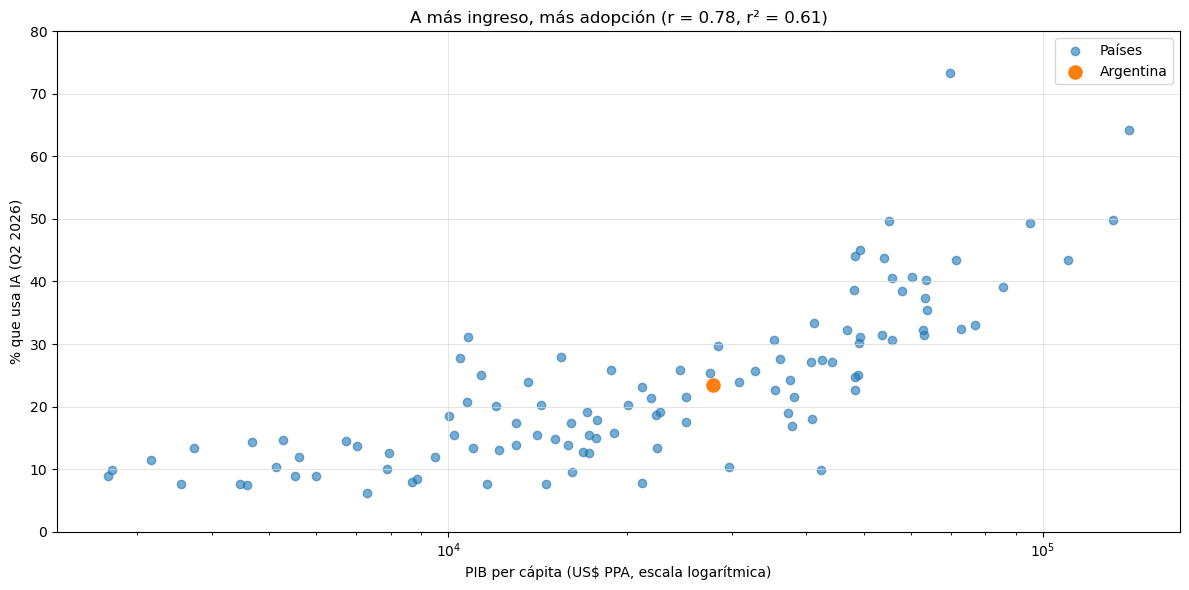

n = 109 | r = 0.78 | r² = 0.61 | p-valor = 8.2e-24


In [43]:
con_pib = medidos.dropna(subset=['pib_per_capita']).copy()
con_pib['log_pib'] = np.log10(con_pib['pib_per_capita'])

r, p_valor = stats.pearsonr(con_pib['log_pib'], con_pib['Q2 2026'])

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(con_pib['pib_per_capita'], con_pib['Q2 2026'], alpha=0.6, label='Países')
arg = con_pib[con_pib['pais'] == 'Argentina']
ax.scatter(arg['pib_per_capita'], arg['Q2 2026'], s=90, color='C1', label='Argentina')

ax.set_xscale('log')
ax.set_ylim([0, 80])
ax.set_xlabel('PIB per cápita (US$ PPA, escala logarítmica)')
ax.set_ylabel('% que usa IA (Q2 2026)')
ax.set_title(f'A más ingreso, más adopción (r = {r:.2f}, r² = {r**2:.2f})')
ax.legend()
ax.grid(True, linewidth=0.5, color='0.85')
plt.tight_layout()
plt.show()
print(f'n = {len(con_pib)} | r = {r:.2f} | r² = {r**2:.2f} | p-valor = {p_valor:.1e}')

**Ingreso vs. adopción.** Cada punto es un país.
- Puse el PIB en escala logarítmica porque va de unos 2.000 a más de 100.000 dólares. Sin log, casi todos los países quedan amontonados a la izquierda.
- La correlación de Pearson da **r = 0,78**: a más ingreso, más adopción, y la relación es fuerte.
- **r² = 0,61** quiere decir que el ingreso acompaña el 61 % de las diferencias de adopción entre países.
- El p-valor es bajísimo, así que no es casualidad.

Pero **correlación no es causalidad**: no puedo decir que ser rico hace que la gente use IA. El ingreso, la educación y el acceso a internet van juntos.

,Ricos %,Pobres %,Diferencia (puntos),Ratio (veces)
H1 2025,32.4,11.1,21.3,2.9
H2 2025,34.7,11.8,23.0,3.0
Q1 2026,37.7,12.8,24.9,2.9
Q2 2026,39.2,13.3,25.9,2.9


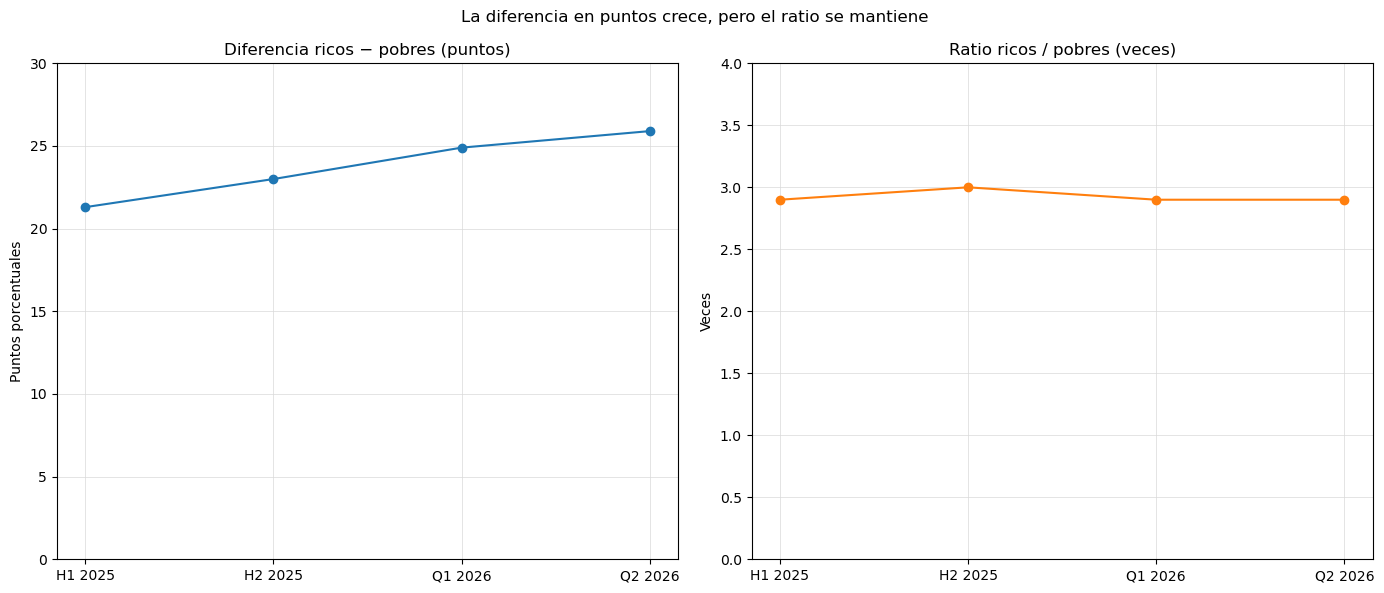

In [44]:
con_pib['cuartil'] = pd.qcut(con_pib['pib_per_capita'], 4, labels=['25% más pobre', '2do', '3ro', '25% más rico'])
por_cuartil = con_pib.groupby('cuartil', observed=True)[PERIODOS].mean()

ricos = por_cuartil.loc['25% más rico']
pobres = por_cuartil.loc['25% más pobre']
brecha = pd.DataFrame({'Ricos %': ricos, 'Pobres %': pobres,
                       'Diferencia (puntos)': ricos - pobres,
                       'Ratio (veces)': ricos / pobres}).round(1)
display(brecha)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].plot(PERIODOS, brecha['Diferencia (puntos)'], marker='o')
axes[0].set_ylim([0, 30])
axes[0].set_title('Diferencia ricos − pobres (puntos)')
axes[0].set_ylabel('Puntos porcentuales')

axes[1].plot(PERIODOS, brecha['Ratio (veces)'], marker='o', color='C1')
axes[1].set_ylim([0, 4])
axes[1].set_title('Ratio ricos / pobres (veces)')
axes[1].set_ylabel('Veces')

for ax in axes:
    ax.grid(True, linewidth=0.5, color='0.85')
fig.suptitle('La diferencia en puntos crece, pero el ratio se mantiene')
plt.tight_layout()
plt.show()

**La brecha entre ricos y pobres.** Dividí los países en 4 grupos según su PIB (cuartiles) y comparé el 25 % más rico con el 25 % más pobre de dos formas:
- **Diferencia (resta):** pasó de 21,3 a 25,9 puntos. **Crece.**
- **Ratio (división):** se queda en ~2,9 veces todo el tiempo. **No cambia.**

¿Cómo puede ser? Un ejemplo simple: 10 vs. 30 da una diferencia de 20 y un ratio de 3. Si los dos crecen un 20 %, queda 12 vs. 36: la diferencia sube a 24 pero el ratio sigue en 3. Acá pasa lo mismo: ricos y pobres crecen más o menos en la misma proporción.

Entonces mi hipótesis **se cumple solo en parte**: la brecha crece en puntos pero no en proporción.

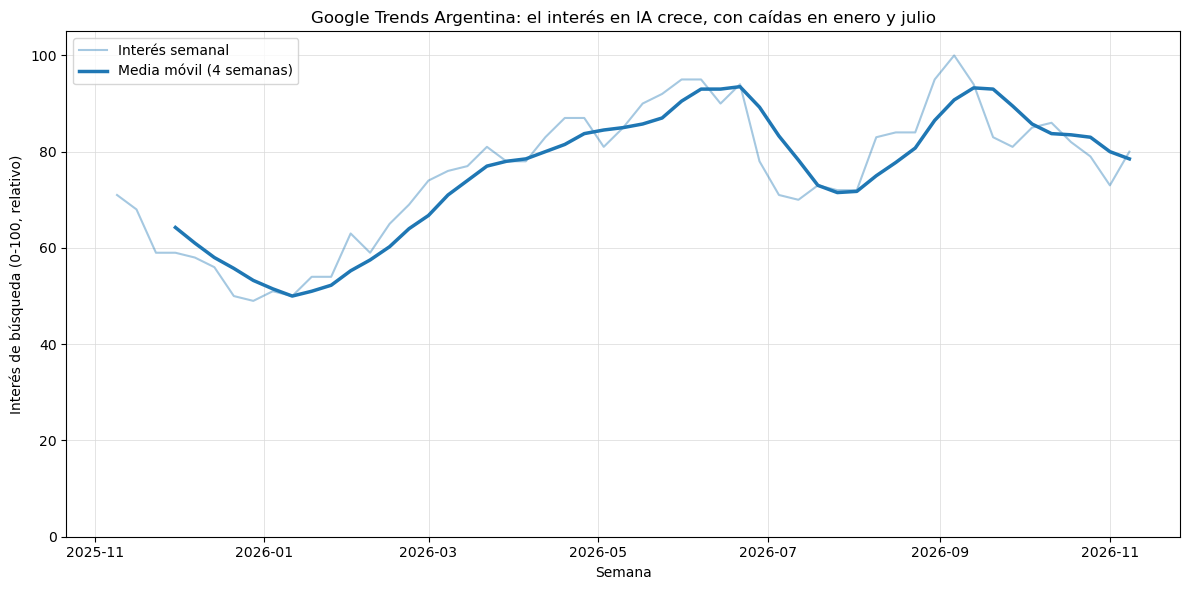

semana
2025-11-30    64.0
2025-12-31    53.0
2026-01-31    52.0
2026-02-28    64.0
2026-03-31    77.0
2026-04-30    84.0
2026-05-31    89.0
2026-06-30    89.0
2026-07-31    72.0
2026-08-31    84.0
2026-09-30    90.0
2026-10-31    83.0
2026-11-30    76.0
Freq: ME, Name: interes, dtype: float64


In [45]:
trends = pd.read_csv('time_series_AR_20251113-1616_20261113-1616.csv', parse_dates=['Time'])
trends.columns = ['semana', 'interes']
trends['media_movil'] = trends['interes'].rolling(4).mean()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(trends['semana'], trends['interes'], alpha=0.4, label='Interés semanal')
ax.plot(trends['semana'], trends['media_movil'], linewidth=2.5, color='C0', label='Media móvil (4 semanas)')
ax.set_ylim([0, 105])
ax.set_xlabel('Semana')
ax.set_ylabel('Interés de búsqueda (0-100, relativo)')
ax.set_title('Google Trends Argentina: el interés en IA crece, con caídas en enero y julio')
ax.legend()
ax.grid(True, linewidth=0.5, color='0.85')
plt.tight_layout()
plt.show()

print(trends.set_index('semana')['interes'].resample('ME').mean().round(0))

**Google Trends Argentina.** Trends no cuenta búsquedas, da un índice de 0 a 100 donde 100 es la semana con más interés. Sirve para ver la forma de la evolución, no cuánta gente usa IA. Le agregué una media móvil de 4 semanas para suavizar los saltos.

- El interés crece: el promedio mensual pasó de 64 en noviembre 2025 a 83 en octubre 2026.
- Hay caídas en enero (vacaciones de verano) y en julio (vacaciones de invierno). Eso da a entender que mucha gente usa IA para estudiar o trabajar.
- Ojo: la caída de julio también coincide con el Mundial 2026, así que no puedo saber cuál de las dos cosas la causó.

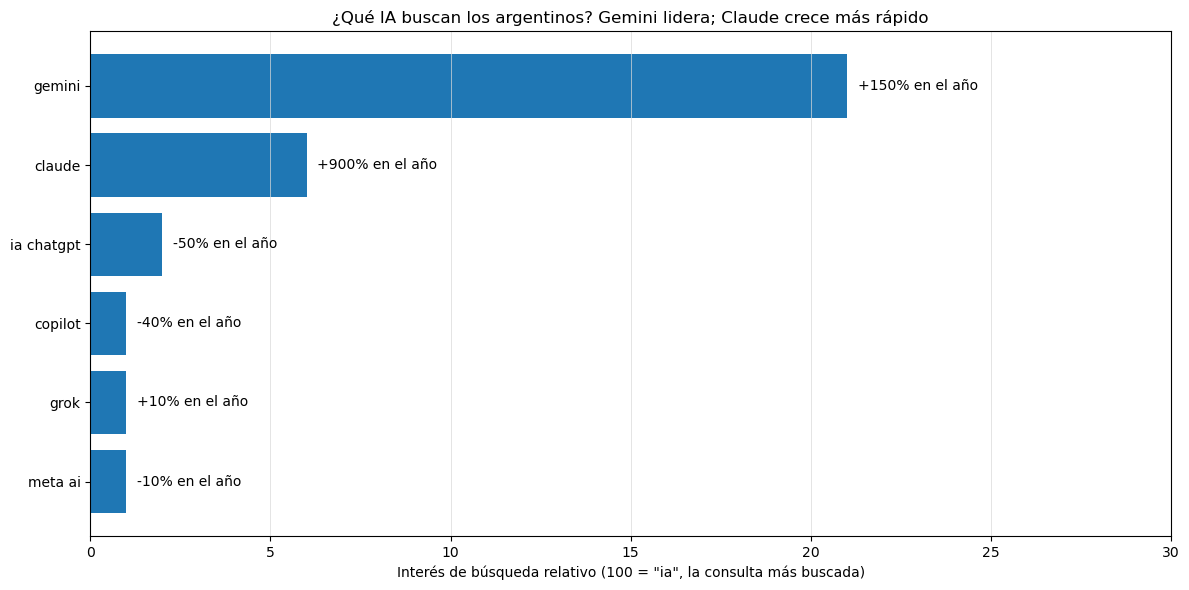

In [46]:
q = pd.read_csv('searched_with_top-searches_queries_AR_20251113-1617_20261113-1617.csv')
herramientas = ['gemini', 'claude', 'ia chatgpt', 'copilot', 'grok', 'meta ai']
q = q[q['query'].isin(herramientas)].copy()
q['variacion'] = q['increase percent'].str.replace(',', '').str.replace('%', '').astype(int)
q = q.sort_values('search interest')

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(q['query'], q['search interest'])
for i, (interes, var) in enumerate(zip(q['search interest'], q['variacion'])):
    ax.text(interes + 0.3, i, f'{var:+d}% en el año', va='center')
ax.set_xlim([0, 30])
ax.set_xlabel('Interés de búsqueda relativo (100 = "ia", la consulta más buscada)')
ax.set_title('¿Qué IA buscan los argentinos? Gemini lidera; Claude crece más rápido')
ax.grid(True, axis='x', linewidth=0.5, color='0.85')
plt.tight_layout()
plt.show()

**¿Qué IA buscan los argentinos?** Saqué las búsquedas relacionadas de cada herramienta.
- **Gemini** es la más buscada (interés 21) y creció +150 % en el año.
- **Claude** creció +900 %, pero desde una base chica (interés 6). Crecer mucho en % no es lo mismo que ser grande, igual que con la brecha.
- Las búsquedas de **"ia chatgpt"** bajaron (-50 %). No quiere decir que se use menos: la gente ya entra directo a ChatGPT sin buscarlo en Google.

## 4. Conclusiones
1. **¿Cuánto?** En el país típico, 1 de cada 5 personas de 15 a 64 años usa IA (mediana 20,7 % en Q2 2026). Argentina está en 23,4 %, un poco arriba de la mediana mundial y de Sudamérica.
2. **¿Cómo evoluciona?** Crece en todos lados: los 111 países medidos subieron entre H1 2025 y Q2 2026. En Google Trends el interés en Argentina también crece, con caídas en las vacaciones.
3. **¿Se agranda la brecha?** Mi hipótesis **se cumple en parte**. En puntos la diferencia entre ricos y pobres crece (de 21 a 26), pero el ratio queda igual (~2,9 veces): los dos grupos crecen en la misma proporción.
4. **Ingreso y adopción van juntos** (r = 0,78), pero eso no prueba que uno cause el otro.
5. En las herramientas, Gemini lidera las búsquedas y Claude es la que más rápido crece.

**Limitaciones**
- El dato de Microsoft es una estimación con datos de Windows, no una encuesta. Puede quedarse corto donde la gente usa IA más desde el celular.
- Saqué 36 países que tenían el promedio de su región en vez de un dato propio.
- Google Trends mide búsquedas, no uso.
- Solo hay 4 períodos (un año), es poco para predecir cómo va a seguir.

**Trabajo futuro:** sumar los próximos trimestres de Microsoft y agregar una encuesta argentina (como la de CEPE-Fundar) para ver quién usa IA dentro del país según edad y educación.